# Practical tasks

##### Please explore the datasets and answer the questions below.
##### Here are some guidlines and advices you should consider:
* you can add as many cells as is comfortable for you for each answer
* some questions require your explanation. Add a cell and choose a markdown option in the menu 
* when you are making plots, please add labels to the axes

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

import seaborn as sns
from sklearn.cluster import KMeans
# you will need to import more libraries as needed

# Clustering tasks

The problem that we are going to solve in this section is to segment customers into different groups based on their shopping trends.

The dataset for this problem `shopping-data.csv`

#### 1. Load the data and preview

In [2]:
customer_data = pd.read_csv('shopping-data.csv')

In [3]:
customer_data.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [4]:
customer_data.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


#### 2. Plot scatter plot for annual income and spending score which will be used for clustering in the next steps

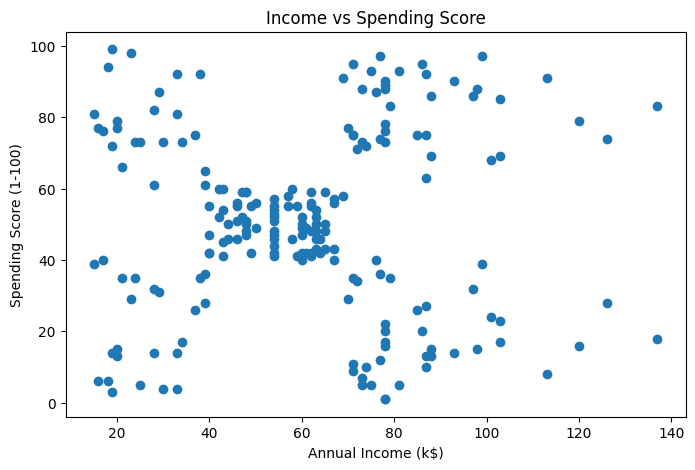

In [5]:
plt.figure(figsize=(8, 5))

plt.scatter(
    customer_data['Annual Income (k$)'],
    customer_data['Spending Score (1-100)']
)

plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Income vs Spending Score')
plt.show()

#### 3. Normalize the data

In [6]:
X = customer_data[['Annual Income (k$)', 'Spending Score (1-100)']]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(X_scaled.shape)
print(X_scaled[:5].round(2))

(200, 2)
[[-1.74 -0.43]
 [-1.74  1.2 ]
 [-1.7  -1.72]
 [-1.7   1.04]
 [-1.66 -0.4 ]]


#### 4. Use Elbow method to decide number of clusters

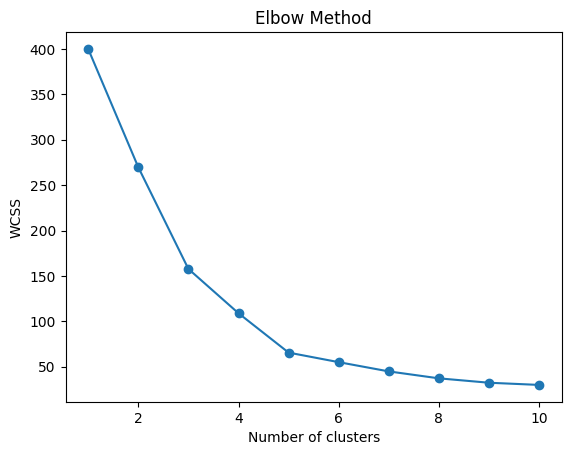

In [7]:
wcss = []

for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    wcss.append(km.inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS')
plt.title('Elbow Method')
plt.show()

#### 5. Perform Clustering using KMeans

In [8]:
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

print(pd.Series(kmeans_labels).value_counts().sort_index())

0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


#### 6. Plot scatter plot and color code in clustered groups

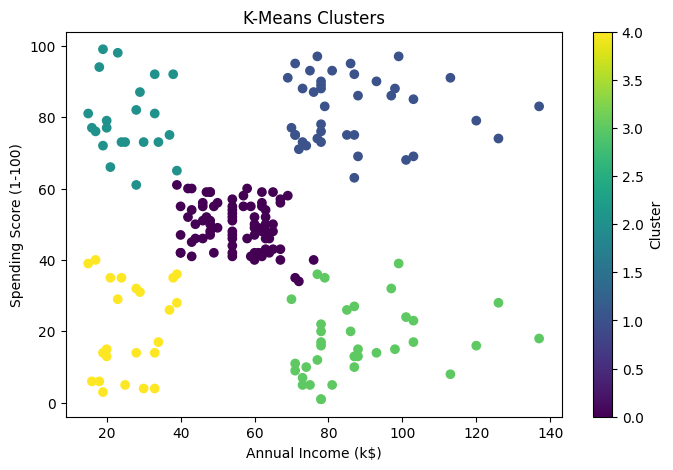

In [9]:
plt.figure(figsize=(8, 5))

plt.scatter(
    customer_data['Annual Income (k$)'],
    customer_data['Spending Score (1-100)'],
    c=kmeans_labels,
    cmap='viridis'
)

plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('K-Means Clusters')
plt.colorbar(label='Cluster')
plt.show()

#### 7. Plot dendrogram to decide number of clusters for Hierarchical Clustering. <br> Explain (free text in a markdown cell) what is the optimal number of clusters and why

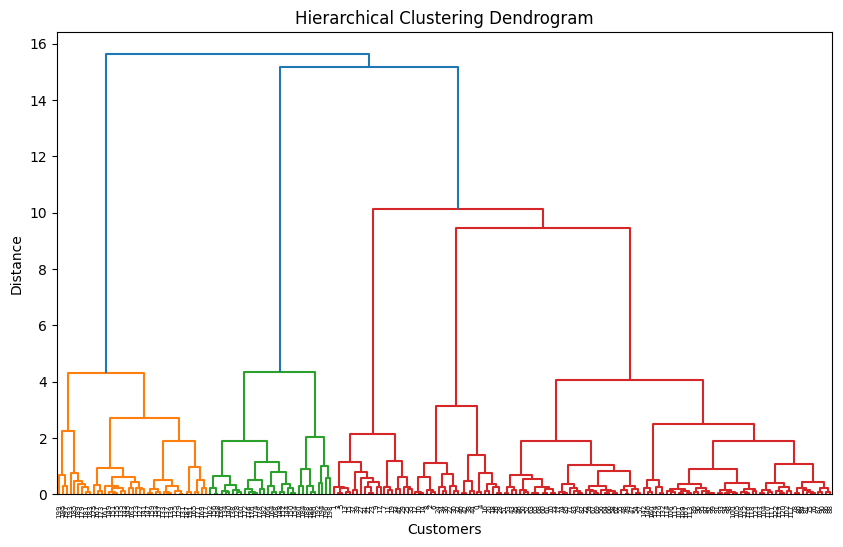

In [10]:
import scipy.cluster.hierarchy as shc

plt.figure(figsize=(10, 6))
shc.dendrogram(shc.linkage(X_scaled, method='ward'))

plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Customers')
plt.ylabel('Distance')
plt.show()

#### 8. Do clustering using Hierarchical Clustering

In [11]:
from sklearn.cluster import AgglomerativeClustering

hc = AgglomerativeClustering(
    n_clusters=5,
    linkage='ward'
)

hc_labels = hc.fit_predict(X_scaled)

print(pd.Series(hc_labels).value_counts().sort_index())

0    32
1    39
2    85
3    21
4    23
Name: count, dtype: int64


#### 9. Plot scatter plot and color code in clustered groups

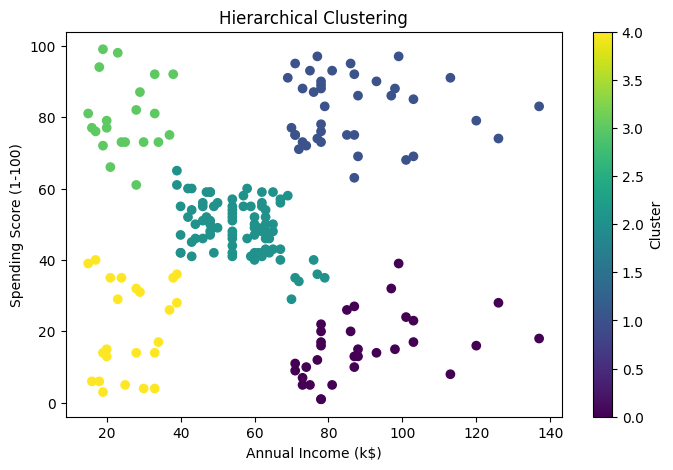

In [12]:
plt.figure(figsize=(8, 5))

plt.scatter(
    customer_data['Annual Income (k$)'],
    customer_data['Spending Score (1-100)'],
    c=hc_labels,
    cmap='viridis'
)

plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Hierarchical Clustering')
plt.colorbar(label='Cluster')
plt.show()

####  10. Do KMeans and DBSCAN clustering on this data

In [13]:
from sklearn.datasets import make_moons
#moons_X: Data, moon_y: Labels
moons_X, moon_y = make_moons(n_samples=2000)

Text(0.5, 1.0, 'Half Moons')

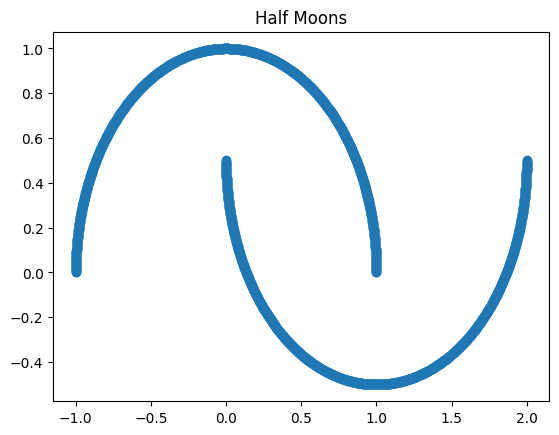

In [14]:
plt.scatter(moons_X[:,0],moons_X[:,1])
plt.title('Half Moons')

#### Using KMeans (do clustering and plot results (each cluster in own color))

In [15]:
moons_kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
moons_kmeans_labels = moons_kmeans.fit_predict(moons_X)

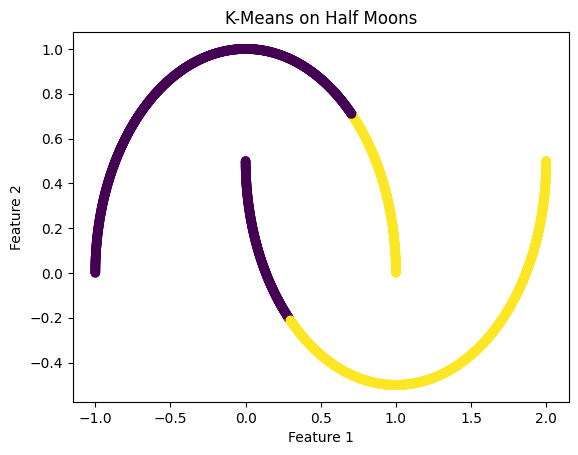

In [16]:
plt.scatter(
    moons_X[:, 0],
    moons_X[:, 1],
    c=moons_kmeans_labels,
    cmap='viridis'
)

plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('K-Means on Half Moons')
plt.show()

#### 11. Using DBSCAN do clustering and plot results (each cluster in own color). Find the most suitable eps and minimal samples number

In [17]:
from sklearn.cluster import DBSCAN

for eps in [0.05, 0.1, 0.2]:
    for min_samples in [5, 10]:
        labels = DBSCAN(
            eps=eps,
            min_samples=min_samples
        ).fit_predict(moons_X)

        clusters = len(set(labels) - {-1})
        noise = sum(labels == -1)

        print(eps, min_samples, clusters, noise)

0.05 5 2 0
0.05 10 2 0
0.1 5 2 0
0.1 10 2 0
0.2 5 2 0
0.2 10 2 0


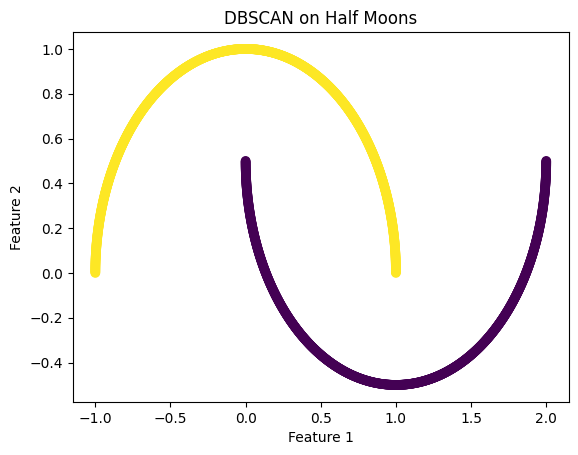

In [18]:
dbscan = DBSCAN(eps=0.1, min_samples=5)
dbscan_labels = dbscan.fit_predict(moons_X)

plt.scatter(
    moons_X[:, 0],
    moons_X[:, 1],
    c=dbscan_labels,
    cmap='viridis'
)

plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('DBSCAN on Half Moons')
plt.show()

#### 12. Compare the results of K-means and DBSCAN clustering
Explain why one or another is prefferable for such dataset, and differences if any.

I think DBSCAN worked better in this case. K-Means couldn't separate the two moons properly because of their shape, while DBSCAN managed to do it. So for this dataset I would choose DBSCAN, although the result also depends on the parameters we use.

### Perform PCA on penguins :)
###### This section uses kaggle dataset (https://www.kaggle.com/datasets/youssefaboelwafa/clustering-penguins-species/data)
###### The tasks below include data analysis, data preprocessing, PCA, and application of classification to predict the target

#### 13. Describe the data. Do any additional exporations as you feel

In [19]:
# Dataset
penguins = pd.read_csv('penguins.csv')
penguins.head()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,MALE
1,39.5,17.4,186.0,3800.0,FEMALE
2,40.3,18.0,195.0,3250.0,FEMALE
3,NaN,NaN,NaN,NaN,NaN
4,36.7,19.3,193.0,3450.0,FEMALE


In [20]:
print('Size:', penguins.shape)
penguins.info()
penguins.describe(include='all').round(2)

Size: (344, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   culmen_length_mm   342 non-null    float64
 1   culmen_depth_mm    342 non-null    float64
 2   flipper_length_mm  342 non-null    float64
 3   body_mass_g        342 non-null    float64
 4   sex                335 non-null    object 
dtypes: float64(4), object(1)
memory usage: 13.6+ KB


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
count,342.00,342.00,342.00,342.00,335
unique,NaN,NaN,NaN,NaN,3
top,NaN,NaN,NaN,NaN,MALE
freq,NaN,NaN,NaN,NaN,169
mean,43.92,17.15,214.01,4201.75,NaN
std,5.46,1.97,260.56,801.95,NaN
min,32.10,13.10,-132.00,2700.00,NaN
25%,39.22,15.60,190.00,3550.00,NaN
50%,44.45,17.30,197.00,4050.00,NaN
75%,48.50,18.70,213.75,4750.00,NaN


#### Based on dataframe describe, in own words explain any abnormal characteristics 

I noticed something strange in the flipper length column. The minimum is -132 mm and the maximum is 5000 mm, which clearly doesn't make sense for a penguin. There are also some missing values, so I think the data needs cleaning before PCA.

#### 14. Explore corrupted data

In [21]:
print(penguins.isna().sum())

missing_rows = penguins[penguins.isna().any(axis=1)]

print('Rows with missing values:', missing_rows.shape)
missing_rows

culmen_length_mm     2
culmen_depth_mm      2
flipper_length_mm    2
body_mass_g          2
sex                  9
dtype: int64
Rows with missing values: (9, 5)


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
3,NaN,NaN,NaN,NaN,NaN
8,34.1,18.1,193.0,3475.0,NaN
10,37.8,17.1,186.0,3300.0,NaN
11,37.8,17.3,180.0,3700.0,NaN
47,37.5,18.9,179.0,2975.0,NaN
246,44.5,14.3,216.0,4100.0,NaN
286,46.2,14.4,214.0,4650.0,NaN
324,47.3,13.8,216.0,4725.0,NaN
339,NaN,NaN,NaN,NaN,NaN


In [22]:
penguins['sex'].value_counts(dropna=False)

sex
MALE      169
FEMALE    165
NaN         9
.           1
Name: count, dtype: int64

In [23]:
bad_flippers = penguins[
    penguins['flipper_length_mm'].notna() &
    ~penguins['flipper_length_mm'].between(150, 250)
]

print(bad_flippers)
print(penguins[penguins['sex'] == '.'])

    culmen_length_mm  culmen_depth_mm  flipper_length_mm  body_mass_g   sex
9               42.0             20.2             5000.0       4250.0  MALE
14              34.6             21.1             -132.0       4400.0  MALE
     culmen_length_mm  culmen_depth_mm  flipper_length_mm  body_mass_g sex
336              44.5             15.7              217.0       4875.0   .


#### 15. Based on observations above, prepare the data for PCA. Only valid rows should be present. <br> Preview dataframe, show its size

In [24]:
numeric_cols = [
    'culmen_length_mm',
    'culmen_depth_mm',
    'flipper_length_mm',
    'body_mass_g'
]

penguins_clean = penguins.copy()
penguins_clean['sex'] = penguins_clean['sex'].replace('.', np.nan)

penguins_clean = penguins_clean.dropna(
    subset=numeric_cols + ['sex']
)

penguins_clean = penguins_clean[
    penguins_clean['flipper_length_mm'].between(150, 250)
]

print('Size:', penguins_clean.shape)
penguins_clean.head()

Size: (332, 5)


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,MALE
1,39.5,17.4,186.0,3800.0,FEMALE
2,40.3,18.0,195.0,3250.0,FEMALE
4,36.7,19.3,193.0,3450.0,FEMALE
5,39.3,20.6,190.0,3650.0,MALE


In [25]:
scaler_penguins = StandardScaler()
X_penguins = scaler_penguins.fit_transform(
    penguins_clean[numeric_cols]
)

print(X_penguins.shape)

(332, 4)


In [26]:
y_penguins = penguins_clean['sex']
print(y_penguins.value_counts())

sex
MALE      167
FEMALE    165
Name: count, dtype: int64


#### 15. Explain the chosen null values handling strategy, how it affects the dataset (pros/cons)

I removed the rows with missing values and the two unrealistic flipper lengths. This leaves 332 rows with valid data. I chose this because it's simple and doesn't require guessing the missing measurements. The downside is that we lose some data, but I think it's reasonable here since the dataset is still large enough for the task. And I kept the original data separately because we'll need the penguins with unknown sex later.


#### 16. Perform PCA with 2 components. Plot the results 

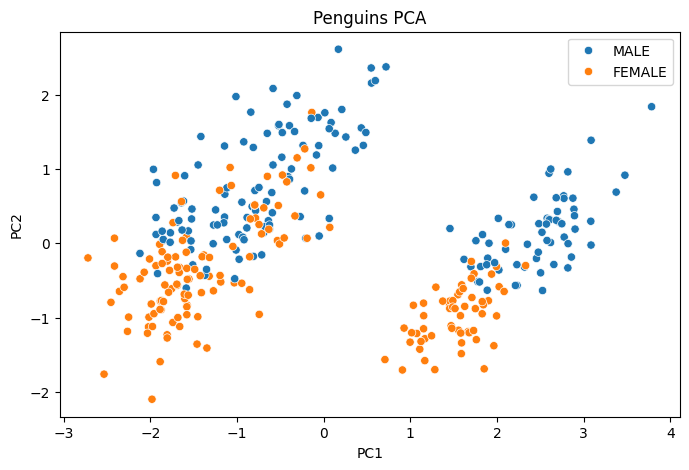

In [27]:
pca = PCA(n_components=2)
X_penguins_pca = pca.fit_transform(X_penguins)

plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=X_penguins_pca[:, 0],
    y=X_penguins_pca[:, 1],
    hue=y_penguins.to_numpy()
)

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Penguins PCA')
plt.show()

#### 17. Display scree plots to determine the optimal number of components and cumulative explained variance

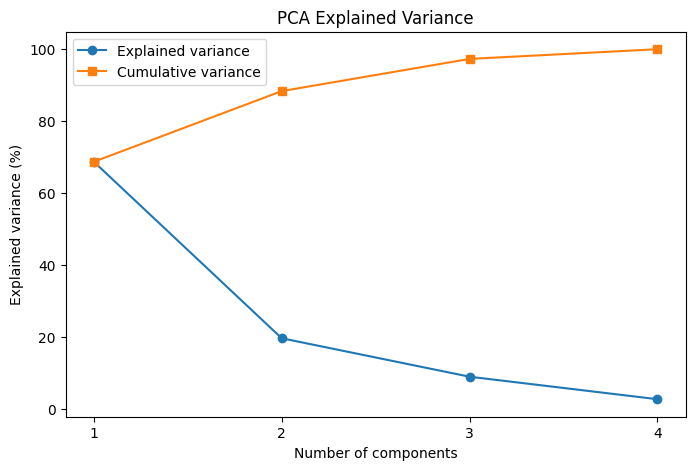

[ 68.71  88.35  97.31 100.  ]


In [28]:
pca_all = PCA()
pca_all.fit(X_penguins)

variance = pca_all.explained_variance_ratio_
components = range(1, len(variance) + 1)

plt.figure(figsize=(8, 5))

plt.plot(components, variance * 100, marker='o', label='Explained variance')
plt.plot(components, np.cumsum(variance) * 100, marker='s', label='Cumulative variance')

plt.xlabel('Number of components')
plt.ylabel('Explained variance (%)')
plt.title('PCA Explained Variance')
plt.xticks(list(components))
plt.legend()
plt.show()

print(np.round(np.cumsum(variance) * 100, 2))

I think 2 components are a reasonable choice here because they keep about 88% of the variance. Using 3 would preserve more information, but 2 are enough for a simple visualization.

#### 18. Calculate (show in numbers) and display component loadings

In [29]:
loadings = pd.DataFrame(
    pca.components_.T * np.sqrt(pca.explained_variance_),
    index=numeric_cols,
    columns=['PC1', 'PC2']
)

loadings.round(2)

,PC1,PC2
culmen_length_mm,0.75,0.54
culmen_depth_mm,-0.66,0.70
flipper_length_mm,0.96,0.00
body_mass_g,0.91,0.06


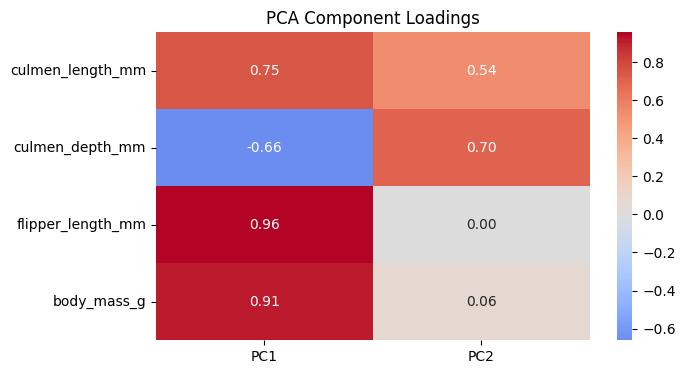

In [30]:
plt.figure(figsize=(7, 4))

sns.heatmap(
    loadings,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title('PCA Component Loadings')
plt.show()

#### 19. Perform logistic regression (or any other classification algorithm) and evaluate the model

In [31]:
# import necessary libraries for model training and evaluation
# Use the PCA-transformed data (X_penguins_pca) and true labels (y_penguins)
# Train and evaluate a model
# <your code here>

Accuracy: 0.82
              precision    recall  f1-score   support

      FEMALE       0.89      0.73      0.80        33
        MALE       0.78      0.91      0.84        34

    accuracy                           0.82        67
   macro avg       0.83      0.82      0.82        67
weighted avg       0.83      0.82      0.82        67



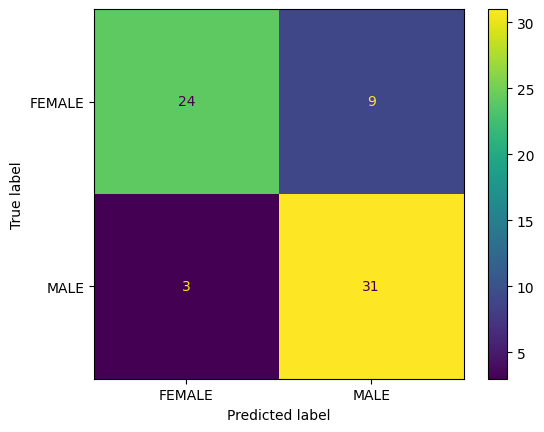

In [32]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

X_train, X_test, y_train, y_test = train_test_split(
    X_penguins_pca,
    y_penguins,
    test_size=0.2,
    random_state=42,
    stratify=y_penguins
)

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

predictions = model.predict(X_test)

print('Accuracy:', round(accuracy_score(y_test, predictions), 2))
print(classification_report(y_test, predictions, digits=2))

ConfusionMatrixDisplay.from_predictions(y_test, predictions)
plt.show()

#### 20. Train the model on all data points, and determine penguin sex for the data, where it was not originally identified

In [33]:
unknown_penguins = penguins.copy()
unknown_penguins['sex'] = unknown_penguins['sex'].replace('.', np.nan)

unknown_penguins = unknown_penguins[
    unknown_penguins['sex'].isna()
].dropna(subset=numeric_cols)

unknown_penguins = unknown_penguins[
    unknown_penguins['flipper_length_mm'].between(150, 250)
]

X_unknown_scaled = scaler_penguins.transform(
    unknown_penguins[numeric_cols]
)

print('Penguins to predict:', len(unknown_penguins))

Penguins to predict: 8


In [34]:
X_unknown_pca = pca.transform(X_unknown_scaled)

print(X_unknown_pca.shape)

(8, 2)


In [35]:
final_model = LogisticRegression(max_iter=1000)
final_model.fit(X_penguins_pca, y_penguins)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [36]:
predicted_sex = final_model.predict(X_unknown_pca)

predicted_penguins = unknown_penguins[numeric_cols].copy()
predicted_penguins['predicted_sex'] = predicted_sex

predicted_penguins.round(2)

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,predicted_sex
8,34.1,18.1,193.0,3475.0,FEMALE
10,37.8,17.1,186.0,3300.0,FEMALE
11,37.8,17.3,180.0,3700.0,FEMALE
47,37.5,18.9,179.0,2975.0,FEMALE
246,44.5,14.3,216.0,4100.0,FEMALE
286,46.2,14.4,214.0,4650.0,FEMALE
324,47.3,13.8,216.0,4725.0,FEMALE
336,44.5,15.7,217.0,4875.0,FEMALE


I trained the final model using all 332 cleaned rows with known sex and used it to predict the missing values. We could make predictions for 8 penguins. (The other 2 had no measurements, so I left them out).
The model predicted FEMALE for all 8 penguins, although these predictions aren't guaranteed to be correct.